Install Model SAM-2

In [6]:
!pip install git+https://github.com/facebookresearch/sam2.git

  Cloning https://github.com/facebookresearch/sam2.git to /tmp/pip-req-build-15ab2hrm
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/sam2.git /tmp/pip-req-build-15ab2hrm
  Resolved https://github.com/facebookresearch/sam2.git to commit 2b90b9f5ceec907a1c18123530e92e794ad901a4
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 2.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 14.7 MB/s eta 0:00:00
  Created wheel for SAM-2: filename=sam_2-1.0-cp313-cp313-linux_x86_64.whl size=535028 sha256=27a681b0a5f3f8bfee9dd65014bc8387b3f2bbc85374a4ca4f2e405438083703
  Stored in directory: /tmp/pip-ephem-wheel-cache-und_waki/wheels/fd/d3/f3/57b6116846666b0608ad34b14e6

In [13]:
!pip install -q transformers

Unzip images folder

In [2]:
!unzip xanh_sm_night.zip

Archive:  xanh_sm_night.zip
   creating: xanh_sm_night/
  inflating: xanh_sm_night/xanh_sm_frame_0270.jpg  
  inflating: xanh_sm_night/xanh_sm_frame_0276.jpg  
  inflating: xanh_sm_night/xanh_sm_frame_0282.jpg  
  inflating: xanh_sm_night/xanh_sm_frame_0288.jpg  
  inflating: xanh_sm_night/xanh_sm_frame_0294.jpg  
  inflating: xanh_sm_night/xanh_sm_frame_0300.jpg  
  inflating: xanh_sm_night/xanh_sm_frame_0306.jpg  
  inflating: xanh_sm_night/xanh_sm_frame_0312.jpg  
  inflating: xanh_sm_night/xanh_sm_frame_0318.jpg  
  inflating: xanh_sm_night/xanh_sm_frame_0324.jpg  


Checking images

Found 10 images. Loading xanh_sm_night/xanh_sm_frame_0270.jpg...


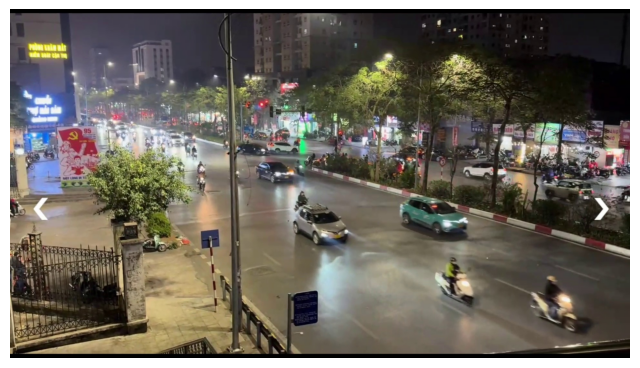

In [3]:
import glob
from PIL import Image
import matplotlib.pyplot as plt

# Set the path containing your images
images_dir_path = "xanh_sm_night"  # Replace with your actual directory path

# Find all image files in the specified directory
image_paths = glob.glob(f"{images_dir_path}/**/*.jpg", recursive=True) + \
              glob.glob(f"{images_dir_path}/**/*.png", recursive=True) + \
              glob.glob(f"{images_dir_path}/**/*.jpeg", recursive=True)

if image_paths:
    print(f"Found {len(image_paths)} images. Loading {image_paths[0]}...")
    image = Image.open(image_paths[0]).convert("RGB")

    # Display the selected image
    plt.figure(figsize=(8, 6))
    plt.imshow(image)
    plt.axis('off')
    plt.show()
else:
    print(f"No images found in '{images_dir_path}'. Please check your path and try again.")

Processing images that detect cars only

In [27]:
import torch
import os
from PIL import Image
import numpy as np

# Import SAM 2 modules
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

# Import Hugging Face Transformers OwlViT for open zero-shot car detection
from transformers import OwlViTProcessor, OwlViTForObjectDetection

# Initialize Models
device = "cuda" if torch.cuda.is_available() else "cpu"

# 1. SAM 2 Setup
sam2_checkpoint = "sam2_hiera_tiny.pt"
model_cfg = "sam2_hiera_t.yaml"
if not os.path.exists(sam2_checkpoint):
    import urllib.request
    urllib.request.urlretrieve(
        "https://dl.fbaipublicfiles.com/segment_anything_2/072824/sam2_hiera_tiny.pt",
        sam2_checkpoint
    )
sam2_model = build_sam2(model_cfg, sam2_checkpoint, device=device)
predictor = SAM2ImagePredictor(sam2_model)

# 2. OwlViT Setup (Open & zero-shot)
processor_owl = OwlViTProcessor.from_pretrained("google/owlvit-base-patch32")
model_owl = OwlViTForObjectDetection.from_pretrained("google/owlvit-base-patch32").to(device)

# Target folders and queries
image_folder = "xanh_sm_night"
TEXT_PROMPTS = [["car", "vehicle", "white car", "taxi"]]
BOX_THRESHOLD = 0.08  # Significantly lower threshold for challenging night-time settings
valid_extensions = (".jpg", ".jpeg", ".png", ".bmp")
results = {}

# Loop over each image in the folder
for filename in sorted(os.listdir(image_folder)):
    if filename.lower().endswith(valid_extensions):
        image_path = os.path.join(image_folder, filename)
        print(f"Processing: {filename}")

        # Load image
        image = Image.open(image_path).convert("RGB")
        image_np = np.array(image)

        # Zero-shot object detection using OwlViT
        inputs = processor_owl(text=TEXT_PROMPTS, images=image, return_tensors="pt").to(device)
        with torch.no_grad():
            outputs = model_owl(**inputs)

        # Post-process results using the underlying image_processor
        target_sizes = torch.tensor([image.size[::-1]]).to(device)
        results_owl = processor_owl.image_processor.post_process_object_detection(
            outputs=outputs,
            threshold=BOX_THRESHOLD,
            target_sizes=target_sizes
        )[0]

        boxes = results_owl["boxes"].cpu().numpy()
        scores = results_owl["scores"].cpu().numpy()

        if len(boxes) == 0:
            print(f"No cars/vehicles detected in {filename}")
            continue

        # Feed detected boxes to SAM 2 to get pixel-perfect masks
        predictor.set_image(image_np)
        masks, sam_scores, logits = predictor.predict(
            point_coords=None,
            point_labels=None,
            box=boxes,
            multimask_output=False
        )

        # Store results
        results[filename] = {
            "masks": masks,
            "scores": sam_scores,
            "boxes": boxes
        }

print(f"Car-only segmentation processing complete! Found results for {len(results)} images.")

Loading weights:   0%|          | 0/412 [00:00<?, ?it/s]

Processing: xanh_sm_frame_0270.jpg
Processing: xanh_sm_frame_0276.jpg
Processing: xanh_sm_frame_0282.jpg
Processing: xanh_sm_frame_0288.jpg
Processing: xanh_sm_frame_0294.jpg
Processing: xanh_sm_frame_0300.jpg
Processing: xanh_sm_frame_0306.jpg
Processing: xanh_sm_frame_0312.jpg
Processing: xanh_sm_frame_0318.jpg
Processing: xanh_sm_frame_0324.jpg
Car-only segmentation processing complete! Found results for 10 images.


Display results

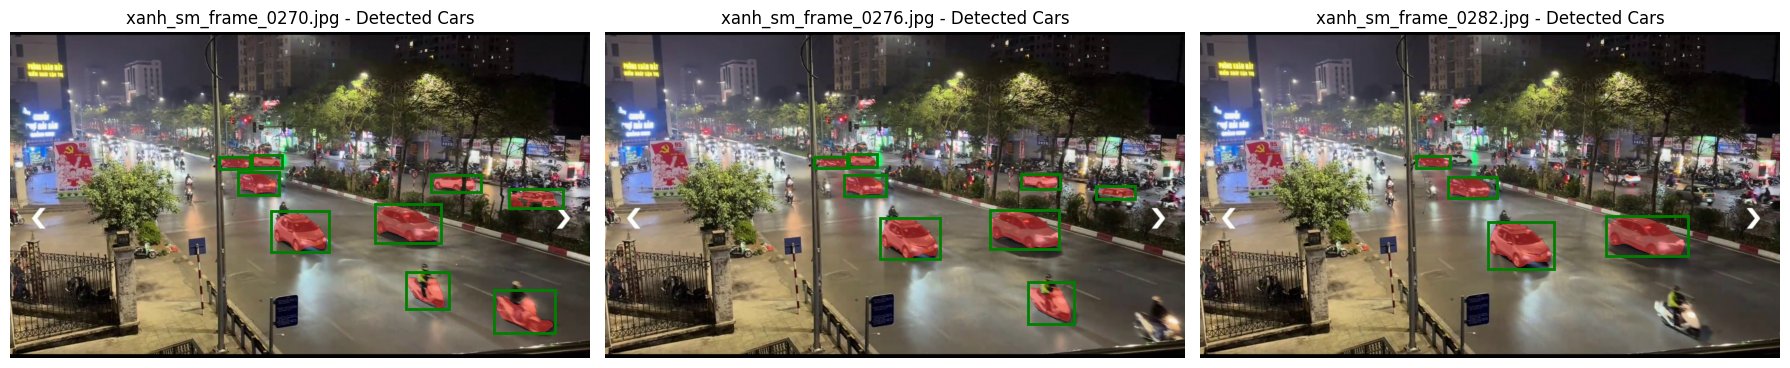

In [28]:
import matplotlib.pyplot as plt
import numpy as np
import os
from PIL import Image

def show_mask(mask, ax, random_color=False):
    if random_color:
        color = np.concatenate([np.random.random(3), np.array([0.6])], axis=0)
    else:
        color = np.array([255/255, 50/255, 50/255, 0.5]) # Translucent red for cars
    h, w = mask.shape[-2:]
    mask_image = mask.reshape(h, w, 1) * color.reshape(1, 1, -1)
    ax.imshow(mask_image)

def show_box(box, ax):
    x0, y0, x1, y1 = box
    rect = plt.Rectangle((x0, y0), x1-x0, y1-y0, edgecolor='green', facecolor='none', lw=2)
    ax.add_patch(rect)

# Visualize a few segmented frames with detected cars
figs_to_show = min(3, len(results))
if figs_to_show > 0:
    fig, axs = plt.subplots(1, figs_to_show, figsize=(18, 6))
    if figs_to_show == 1:
        axs = [axs]

    for i, (filename, data) in enumerate(list(results.items())[:figs_to_show]):
        image_path = os.path.join(image_folder, filename)
        image = Image.open(image_path).convert("RGB")

        axs[i].imshow(image)

        # Plot all car detections
        for box, mask in zip(data["boxes"], data["masks"]):
            show_box(box, axs[i])
            # Since multimask_output=False, the mask shape is (1, H, W)
            # We squeeze to (H, W) or grab the first index for show_mask
            show_mask(mask[0], axs[i])

        axs[i].set_title(f"{filename} - Detected Cars")
        axs[i].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("No results to display. Please verify that images are correctly processed.")

Count how many cars detected & calculate IoU

In [29]:
def calculate_iou(mask1, mask2):
    """Calculates the Intersection over Union (IoU) between two binary boolean masks."""
    intersection = np.logical_and(mask1, mask2).sum()
    union = np.logical_or(mask1, mask2).sum()
    if union == 0:
        return 0.0
    return float(intersection / union)

# Compute refinement IoUs
# This measures the alignment between the rough bounding box prompt and the final SAM 2 segmented mask
all_ious = []

for filename, data in results.items():
    image_path = os.path.join(image_folder, filename)
    image = Image.open(image_path)
    width, height = image.size

    for box, mask in zip(data["boxes"], data["masks"]):
        # 1. Create a binary mask representing the solid bounding box area
        box_mask = np.zeros((height, width), dtype=bool)
        x0, y0, x1, y1 = map(int, box)
        # Clip coordinates to image boundary
        x0, x1 = max(0, x0), min(width, x1)
        y0, y1 = max(0, y0), min(height, y1)
        box_mask[y0:y1, x0:x1] = True

        # 2. Extract SAM 2 mask
        sam_mask = mask[0] > 0.0 # Convert to boolean

        # 3. Compute IoU
        iou_score = calculate_iou(box_mask, sam_mask)
        all_ious.append(iou_score)

mean_iou = np.mean(all_ious) if all_ious else 0.0
print(f"--- Segmentation Metrics Summary ---")
print(f"Total segmented car instances evaluated: {len(all_ious)}")
print(f"Mean IoU (SAM 2 Mask vs. Detector Box): {mean_iou:.4f}")


--- Segmentation Metrics Summary ---
Total segmented car instances evaluated: 54
Mean IoU (SAM 2 Mask vs. Detector Box): 0.6273
